# Unit 10 — Mengevaluasi Hasil Pemodelan
**Kode unit:** J.62DMI00.014.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini adalah **satu-satunya** tempat data uji dipakai. Model final dievaluasi terhadap kriteria sukses T1–T5 (dibaca otomatis dari Unit 2), dibandingkan dengan tiga baseline, lalu dianalisis lebih dalam: matriks konfusi, kurva ROC, faktor pendorong (*permutation importance*), tingkat keyakinan, stabilitas per tahun, dan makna ekonomi sinyal.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

def to_json(obj, path):
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))

In [2]:
import joblib
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

train = pd.read_csv(PROC / 'train.csv', parse_dates=['Date'])
test = pd.read_csv(PROC / 'test.csv', parse_dates=['Date'])
model = joblib.load(MOD / 'best_model.pkl')
with open(MOD / 'model_metadata.json') as f:
    meta = json.load(f)
with open(REP / 'technical_objective.json', encoding='utf-8') as f:
    tech = json.load(f)
with open(REP / 'split_info.json') as f:
    split_info = json.load(f)
FEATURES = meta['features']
X_te, y_te = test[FEATURES], test.y
proba = model.predict_proba(X_te)[:, 1]
pred = (proba >= meta['threshold']).astype(int)
print(f'Model: {meta["model_name"]} | data uji: {len(test):,} hari ({test.Date.min():%d %b %Y} – {test.Date.max():%d %b %Y})')
print(f'Proporsi naik aktual di data uji: {y_te.mean():.1%} | proporsi diprediksi naik: {pred.mean():.1%}')

Model: Random Forest | data uji: 787 hari (25 Jan 2023 – 26 May 2026)
Proporsi naik aktual di data uji: 52.7% | proporsi diprediksi naik: 55.0%


## 1. Metrik model dan baseline pada data uji

In [3]:
def evaluate(y_true, y_pred, score):
    return {'accuracy': accuracy_score(y_true, y_pred), 'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'f1_macro': f1_score(y_true, y_pred, average='macro'),
            'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'roc_auc': roc_auc_score(y_true, score)}


results = {'Model: ' + meta['model_name']: evaluate(y_te, pred, proba)}
b1 = DummyClassifier(strategy='most_frequent').fit(train[FEATURES], train.y)
results['B1 Mayoritas'] = evaluate(y_te, b1.predict(X_te), b1.predict_proba(X_te)[:, 1])
b2 = DummyClassifier(strategy='stratified', random_state=RANDOM_STATE).fit(train[FEATURES], train.y)
results['B2 Acak berstrata'] = evaluate(y_te, b2.predict(X_te), b2.predict_proba(X_te)[:, 1])
results['B3 Ikuti S&P 500'] = evaluate(y_te, (X_te.sp500_ret > 0).astype(int), X_te.sp500_ret)
res_df = pd.DataFrame(results).T
display(res_df)
m = res_df.iloc[0]

,accuracy,balanced_accuracy,f1_macro,precision_macro,recall_macro,roc_auc
Model: Random Forest,0.5604,0.5578,0.5577,0.5582,0.5578,0.5691
B1 Mayoritas,0.5273,0.5000,0.3453,0.2637,0.5000,0.5000
B2 Acak berstrata,0.5133,0.5107,0.5105,0.5108,0.5107,0.5107
B3 Ikuti S&P 500,0.5527,0.5500,0.5498,0.5504,0.5500,0.5801


## 2. Pemeriksaan kriteria sukses teknis (T1–T5 dari Unit 2)

In [4]:
k = tech['kpi']
naive = res_df.loc[['B1 Mayoritas', 'B2 Acak berstrata']]
beats_naive = all((m[c] > naive[c]).all() for c in ['accuracy', 'f1_macro', 'roc_auc'])
no_leak = split_info['pit_test']['passed'] and split_info['purge_rows'] >= 1
kpi_rows = [
    ('T1', 'Accuracy', m.accuracy, f'≥ {k["T1_accuracy_min"]}', m.accuracy >= k['T1_accuracy_min']),
    ('T2', 'F1-macro', m.f1_macro, f'≥ {k["T2_f1_macro_min"]}', m.f1_macro >= k['T2_f1_macro_min']),
    ('T3', 'ROC-AUC', m.roc_auc, f'≥ {k["T3_roc_auc_min"]}', m.roc_auc >= k['T3_roc_auc_min']),
    ('T4', 'Mengalahkan B1 & B2 (accuracy, F1, AUC)', np.nan, 'semua lebih tinggi', beats_naive),
    ('T5', 'Tanpa kebocoran data', np.nan, 'uji PIT lulus + purging', no_leak),
]
kpi_df = pd.DataFrame(kpi_rows, columns=['Kode', 'Kriteria', 'Nilai', 'Ambang', 'Lulus'])
kpi_df['Lulus'] = kpi_df.Lulus.astype(bool)
kpi_df['Status'] = np.where(kpi_df.Lulus, 'LULUS', 'TIDAK LULUS')
display(kpi_df.drop(columns='Lulus').assign(Nilai=kpi_df.Nilai.map(lambda v: '-' if pd.isna(v) else f'{v:.4f}')))
all_pass = bool(kpi_df.Lulus.all())
b3m = res_df.loc['B3 Ikuti S&P 500']
print(f'Semua kriteria terpenuhi: {all_pass}')
print(f'Dibanding baseline domain B3: accuracy {m.accuracy - b3m.accuracy:+.3f}, F1 {m.f1_macro - b3m.f1_macro:+.3f}, '
      f'AUC {m.roc_auc - b3m.roc_auc:+.3f}')

,Kode,Kriteria,Nilai,Ambang,Status
0,T1,Accuracy,0.5604,≥ 0.55,LULUS
1,T2,F1-macro,0.5577,≥ 0.55,LULUS
2,T3,ROC-AUC,0.5691,≥ 0.58,TIDAK LULUS
3,T4,"Mengalahkan B1 & B2 (accuracy, F1, AUC)",-,semua lebih tinggi,LULUS
4,T5,Tanpa kebocoran data,-,uji PIT lulus + purging,LULUS


Semua kriteria terpenuhi: False
Dibanding baseline domain B3: accuracy +0.008, F1 +0.008, AUC -0.011


## 3. Matriks konfusi dan kurva ROC

                 precision    recall  f1-score   support

Turun/Tetap (0)      0.537     0.511     0.523       372
       Naik (1)      0.580     0.605     0.592       415

       accuracy                          0.560       787
      macro avg      0.558     0.558     0.558       787
   weighted avg      0.559     0.560     0.560       787



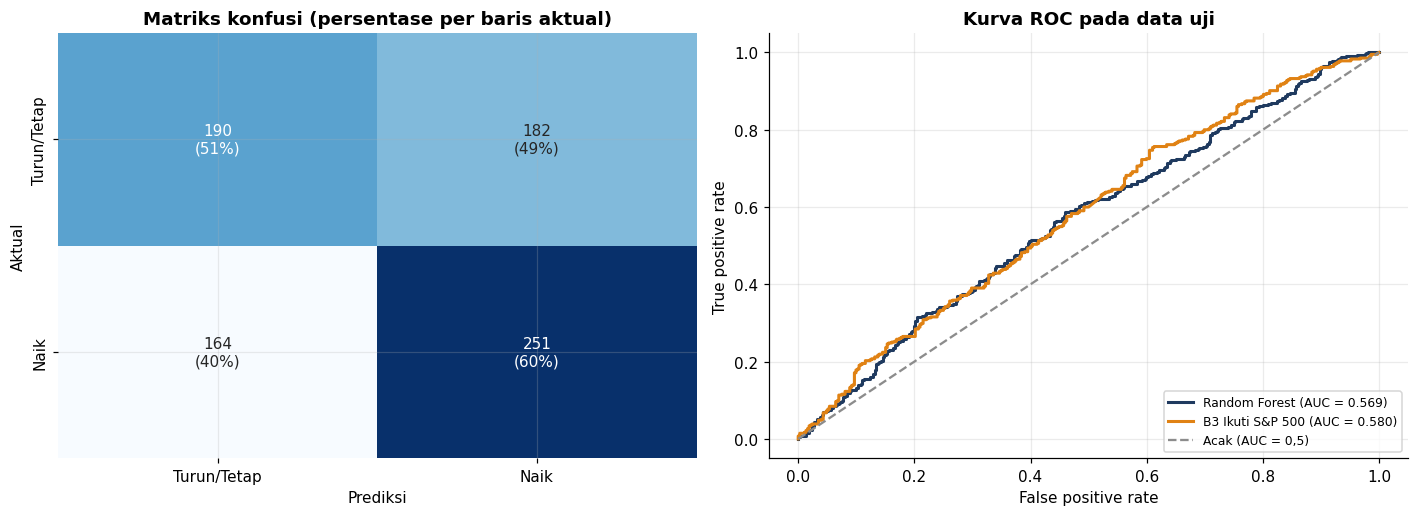

In [5]:
cm = confusion_matrix(y_te, pred)
print(classification_report(y_te, pred, target_names=['Turun/Tetap (0)', 'Naik (1)'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
cm_pct = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_pct, annot=np.array([[f'{cm[i, j]}\n({cm_pct[i, j]:.0%})' for j in range(2)] for i in range(2)]),
            fmt='', cmap='Blues', cbar=False, ax=ax, xticklabels=['Turun/Tetap', 'Naik'], yticklabels=['Turun/Tetap', 'Naik'])
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual'); ax.set_title('Matriks konfusi (persentase per baris aktual)')
ax = axes[1]
for name, score, col in [(meta['model_name'], proba, C_NAVY), ('B3 Ikuti S&P 500', X_te.sp500_ret, C_ACCENT)]:
    fpr, tpr, _ = roc_curve(y_te, score)
    ax.plot(fpr, tpr, color=col, lw=2, label=f'{name} (AUC = {roc_auc_score(y_te, score):.3f})')
ax.plot([0, 1], [0, 1], color=C_GREY, ls='--', label='Acak (AUC = 0,5)')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('Kurva ROC pada data uji')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(FIG / '10_confusion_roc.png')
plt.show()

## 4. Faktor pendorong: *permutation importance* pada data uji
Nilai satu fitur diacak 30 kali; penurunan ROC-AUC menunjukkan seberapa besar model bergantung pada fitur tersebut
untuk data yang **belum pernah dilihat**. Metode ini berlaku untuk semua jenis model.

,fitur,penurunan_auc,std
0,sp500_ret,0.0453,0.0210
1,vix_chg,0.0204,0.0095
2,ihsg_ret_lag2,0.0007,0.0031
3,ihsg_ret,0.0005,0.0016
4,oil_ret,0.0003,0.0034
5,rate_spread,0.0000,0.0000
6,vix_level,-0.0002,0.0017
7,ihsg_ret_lag3,-0.0007,0.0013
8,ihsg_vol_10d,-0.0007,0.0018
9,gold_ret,-0.0009,0.0029


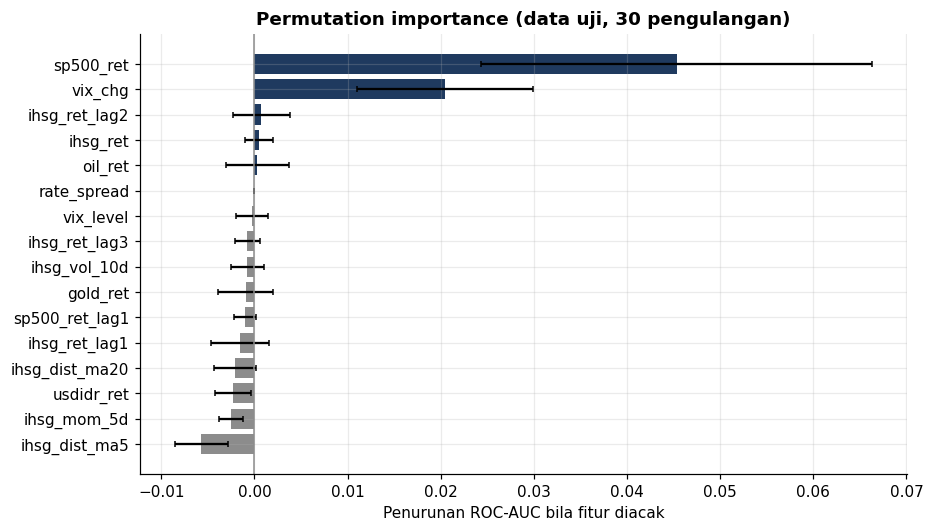

In [6]:
pi = permutation_importance(model, X_te, y_te, scoring='roc_auc', n_repeats=30, random_state=RANDOM_STATE)
perm = pd.DataFrame({'fitur': FEATURES, 'penurunan_auc': pi.importances_mean, 'std': pi.importances_std}) \
         .sort_values('penurunan_auc', ascending=False).reset_index(drop=True)
display(perm)
fig, ax = plt.subplots(figsize=(9, 5.2))
pp = perm.iloc[::-1]
ax.barh(pp.fitur, pp.penurunan_auc, xerr=pp['std'], color=[C_NAVY if v > 0 else C_GREY for v in pp.penurunan_auc], capsize=2)
ax.axvline(0, color=C_GREY, lw=1)
ax.set_xlabel('Penurunan ROC-AUC bila fitur diacak'); ax.set_title('Permutation importance (data uji, 30 pengulangan)')
plt.savefig(FIG / '10_permutation_importance.png')
plt.show()

## 5. Tingkat keyakinan: apakah prediksi yang lebih yakin lebih akurat?
Keyakinan = $|P(\text{Naik}) - 0{,}5|$. Hari-hari diurutkan dari prediksi paling yakin; akurasi dihitung untuk
sebagian hari teratas (*coverage*). Ini menjadi dasar "zona keyakinan" untuk kebutuhan manajemen risiko.

,hari,akurasi,p_min,p_max
keyakinan,,,,
Rendah,262,0.5611,0.4479,0.5531
Sedang,262,0.5344,0.3878,0.6121
Tinggi,263,0.5856,0.2193,0.7254


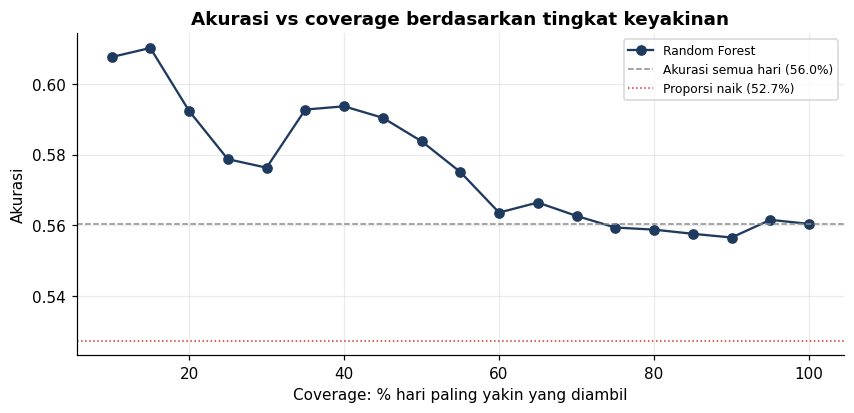

In [7]:
conf = np.abs(proba - 0.5)
order = np.argsort(-conf)
correct = (pred == y_te.values)[order]
cov = np.arange(0.1, 1.0001, 0.05)
cov_acc = [correct[:max(1, int(round(c * len(correct))))].mean() for c in cov]

terc = pd.qcut(pd.Series(conf), 3, labels=['Rendah', 'Sedang', 'Tinggi'])
conf_tbl = pd.DataFrame({'keyakinan': terc, 'benar': pred == y_te.values, 'proba': proba}).groupby('keyakinan', observed=True).agg(
    hari=('benar', 'size'), akurasi=('benar', 'mean'), p_min=('proba', 'min'), p_max=('proba', 'max'))
display(conf_tbl)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(cov * 100, cov_acc, marker='o', color=C_NAVY, label=meta['model_name'])
ax.axhline(m.accuracy, color=C_GREY, ls='--', lw=1, label=f'Akurasi semua hari ({m.accuracy:.1%})')
ax.axhline(y_te.mean(), color=C_DOWN, ls=':', lw=1, label=f'Proporsi naik ({y_te.mean():.1%})')
ax.set_xlabel('Coverage: % hari paling yakin yang diambil'); ax.set_ylabel('Akurasi')
ax.set_title('Akurasi vs coverage berdasarkan tingkat keyakinan')
ax.legend(fontsize=8)
plt.savefig(FIG / '10_confidence_coverage.png')
plt.show()

## 6. Stabilitas per tahun dan makna ekonomi sinyal

,hari,proporsi_naik,akurasi_model,akurasi_B3,akurasi_B1
tahun,,,,,
2023,223.0000,0.5516,0.6009,0.5919,0.5516
2024,237.0000,0.5105,0.5443,0.4937,0.5105
2025,236.0000,0.5593,0.5339,0.5381,0.5593
2026,91.0000,0.4286,0.5714,0.6484,0.4286


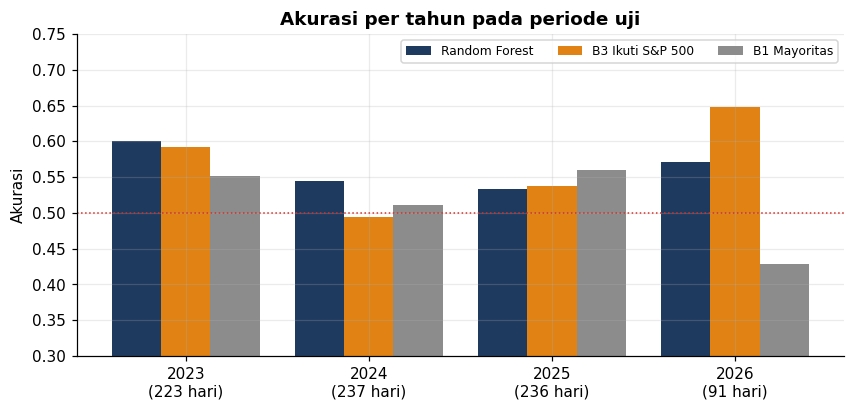

Rata-rata return IHSG hari berikutnya | diprediksi Naik: +0.143% (433 hari) | diprediksi Turun: -0.193% (354 hari) | uji Welch p = 0.0000
Catatan: ini return penutupan-ke-penutupan; sinyal baru tersedia setelah BEI tutup, sehingga angka ini mengukur kualitas informasi, BUKAN keuntungan strategi trading.


In [8]:
ev = test[['Date', 'y', 'ret_next']].assign(pred=pred, proba=proba, b3=(X_te.sp500_ret > 0).astype(int).values)
yearly = ev.groupby(ev.Date.dt.year).apply(lambda g: pd.Series({
    'hari': len(g), 'proporsi_naik': g.y.mean(),
    'akurasi_model': (g.pred == g.y).mean(), 'akurasi_B3': (g.b3 == g.y).mean(),
    'akurasi_B1': (g.y == int(train.y.mode()[0])).mean()}))
yearly.index.name = 'tahun'
display(yearly)

fig, ax = plt.subplots(figsize=(9, 3.8))
xs = np.arange(len(yearly)); w = 0.27
ax.bar(xs - w, yearly.akurasi_model, w, color=C_NAVY, label=meta['model_name'])
ax.bar(xs, yearly.akurasi_B3, w, color=C_ACCENT, label='B3 Ikuti S&P 500')
ax.bar(xs + w, yearly.akurasi_B1, w, color=C_GREY, label='B1 Mayoritas')
ax.axhline(0.5, color=C_DOWN, ls=':', lw=1)
ax.set_xticks(xs); ax.set_xticklabels([f'{y}\n({int(n)} hari)' for y, n in zip(yearly.index, yearly.hari)])
ax.set_ylim(0.3, max(0.75, yearly[['akurasi_model', 'akurasi_B3', 'akurasi_B1']].max().max() + 0.05))
ax.set_ylabel('Akurasi'); ax.set_title('Akurasi per tahun pada periode uji'); ax.legend(fontsize=8, ncol=3)
plt.savefig(FIG / '10_yearly_accuracy.png')
plt.show()

r_up, r_dn = ev.loc[ev.pred == 1, 'ret_next'], ev.loc[ev.pred == 0, 'ret_next']
t_stat, p_val = stats.ttest_ind(r_up, r_dn, equal_var=False)
econ = {'mean_ret_pred_naik': r_up.mean(), 'mean_ret_pred_turun': r_dn.mean(), 'n_pred_naik': len(r_up),
        'n_pred_turun': len(r_dn), 't_stat': t_stat, 'p_value': p_val}
print(f'Rata-rata return IHSG hari berikutnya | diprediksi Naik: {r_up.mean():+.3f}% ({len(r_up)} hari) '
      f'| diprediksi Turun: {r_dn.mean():+.3f}% ({len(r_dn)} hari) | uji Welch p = {p_val:.4f}')
print('Catatan: ini return penutupan-ke-penutupan; sinyal baru tersedia setelah BEI tutup, sehingga angka ini '
      'mengukur kualitas informasi, BUKAN keuntungan strategi trading.')

In [9]:
evaluation = {
    'model': meta['model_name'], 'threshold': meta['threshold'], 'n_test': len(test),
    'test_period': [f'{test.Date.min():%Y-%m-%d}', f'{test.Date.max():%Y-%m-%d}'], 'test_up_share': float(y_te.mean()),
    'metrics': res_df.iloc[0].to_dict(), 'baselines': res_df.iloc[1:].to_dict('index'),
    'kpi': kpi_df.drop(columns='Status').to_dict('records'), 'all_kpi_passed': all_pass,
    'vs_B3': {c: float(m[c] - b3m[c]) for c in ['accuracy', 'f1_macro', 'roc_auc']},
    'confusion_matrix': cm.tolist(), 'permutation_importance': perm.to_dict('records'),
    'confidence_terciles': conf_tbl.reset_index().to_dict('records'),
    'coverage_accuracy': dict(zip([round(c, 2) for c in cov], cov_acc)),
    'yearly': yearly.reset_index().to_dict('records'), 'economic': econ,
}
to_json(evaluation, REP / 'evaluation_metrics.json')
ev.to_csv(REP / 'test_predictions.csv', index=False)

passed = ', '.join(kpi_df.loc[kpi_df.Lulus, 'Kode']); failed = ', '.join(kpi_df.loc[~kpi_df.Lulus, 'Kode']) or '-'
top3 = ', '.join(perm.fitur.head(3))
hi = conf_tbl.loc['Tinggi']
display(Markdown(f'''
### Ringkasan Unit 10
- **{meta["model_name"]}** pada {len(test):,} hari uji ({test.Date.min():%b %Y} – {test.Date.max():%b %Y}):
  accuracy **{m.accuracy:.3f}**, F1-macro **{m.f1_macro:.3f}**, ROC-AUC **{m.roc_auc:.3f}**.
- Kriteria lulus: **{passed}**; tidak lulus: **{failed}**.
- Dibanding B3 "ikuti S&P 500": selisih accuracy {m.accuracy - b3m.accuracy:+.3f}, F1 {m.f1_macro - b3m.f1_macro:+.3f}, AUC {m.roc_auc - b3m.roc_auc:+.3f}.
- Faktor pendorong utama (permutation importance): {top3}.
- Sepertiga hari dengan keyakinan tertinggi: akurasi {hi.akurasi:.1%} ({int(hi.hari)} hari).
- Akurasi per tahun berkisar {yearly.akurasi_model.min():.1%} – {yearly.akurasi_model.max():.1%}.
'''))


### Ringkasan Unit 10
- **Random Forest** pada 787 hari uji (Jan 2023 – May 2026):
  accuracy **0.560**, F1-macro **0.558**, ROC-AUC **0.569**.
- Kriteria lulus: **T1, T2, T4, T5**; tidak lulus: **T3**.
- Dibanding B3 "ikuti S&P 500": selisih accuracy +0.008, F1 +0.008, AUC -0.011.
- Faktor pendorong utama (permutation importance): sp500_ret, vix_chg, ihsg_ret_lag2.
- Sepertiga hari dengan keyakinan tertinggi: akurasi 58.6% (263 hari).
- Akurasi per tahun berkisar 53.4% – 60.1%.
